In [1]:
import gc                                # garbage collector, used to free RAM
import numpy as np                       # NumPy: numerical arrays
import pandas as pd                      # pandas: tables
import scanpy as sc                      # Scanpy: single-cell analysis
import matplotlib.pyplot as plt          # matplotlib: plotting
from pathlib import Path                 # Path: file and folder paths

project_dir = Path.cwd().parent          # notebook lives in Notebook/, so parent = project root
proc_dir   = project_dir / "data" / "processed"
fig_dir    = project_dir / "Figure"
result_dir = project_dir / "Result"      # small result tables (CSV) go here and can be uploaded to GitHub
result_dir.mkdir(parents=True, exist_ok=True)

labels = ["D7", "D14", "D21"]            # fixed order, used for tables and plots
assert all((proc_dir / f"{s}_cells.h5ad").exists() for s in labels), "Missing .h5ad file(s) from notebook 03"
print("Setup OK")

Setup OK


In [2]:
qc_tables = {}                                              # label -> small table of QC metrics

for label in labels:
    a = sc.read_h5ad(proc_dir / f"{label}_cells.h5ad")      # load one sample at a time
    a.var["mt"]   = a.var_names.str.startswith("MT-")       # True for mitochondrial genes (symbols starting with "MT-")
    a.var["ribo"] = a.var_names.str.startswith(("RPS", "RPL"))  # True for ribosomal protein genes
    # Adds per-cell: total_counts, n_genes_by_counts, pct_counts_mt, pct_counts_ribo
    sc.pp.calculate_qc_metrics(a, qc_vars=["mt", "ribo"], percent_top=None, log1p=False, inplace=True)
    cols = ["timepoint", "total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
    qc_tables[label] = a.obs[cols].copy()                   # keep only the small obs table
    print(label, a.shape, "| mito genes:", int(a.var["mt"].sum()), "| ribo genes:", int(a.var["ribo"].sum()))
    del a                                                   # drop the big matrix from memory
    gc.collect()

qc = pd.concat(qc_tables.values())                          # stack the 3 tables into one
qc.to_csv(result_dir / "qc_metrics_before_filtering.csv")   # save for reproducibility
print(qc.shape)

D7 (5977, 36601) | mito genes: 13 | ribo genes: 103
D14 (3996, 36601) | mito genes: 13 | ribo genes: 103
D21 (6833, 36601) | mito genes: 13 | ribo genes: 103
(16806, 5)


In [3]:
cols = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
# For each sample, show the 1st, 5th, 50th (median), 95th and 99th percentiles of each metric
summary = qc.groupby("timepoint")[cols].quantile([0.01, 0.05, 0.5, 0.95, 0.99]).round(1)
print(summary)

                total_counts  n_genes_by_counts  pct_counts_mt  \
timepoint                                                        
D14       0.01        5135.0             1021.4            0.5   
          0.05        5797.0             1643.5            1.3   
          0.50       36437.5             5905.0            7.6   
          0.95      146355.2             9319.0           48.8   
          0.99      223650.6            10489.4           76.1   
D21       0.01         586.0              184.3            0.2   
          0.05        1064.0              354.6            0.9   
          0.50       19032.0             3752.0            7.4   
          0.95       73510.4             7814.4           67.2   
          0.99      122592.0             9683.8           89.2   
D7        0.01        1035.0              223.8            0.2   
          0.05        1218.0              449.0            2.3   
          0.50       24376.0             4246.0            8.7   
          

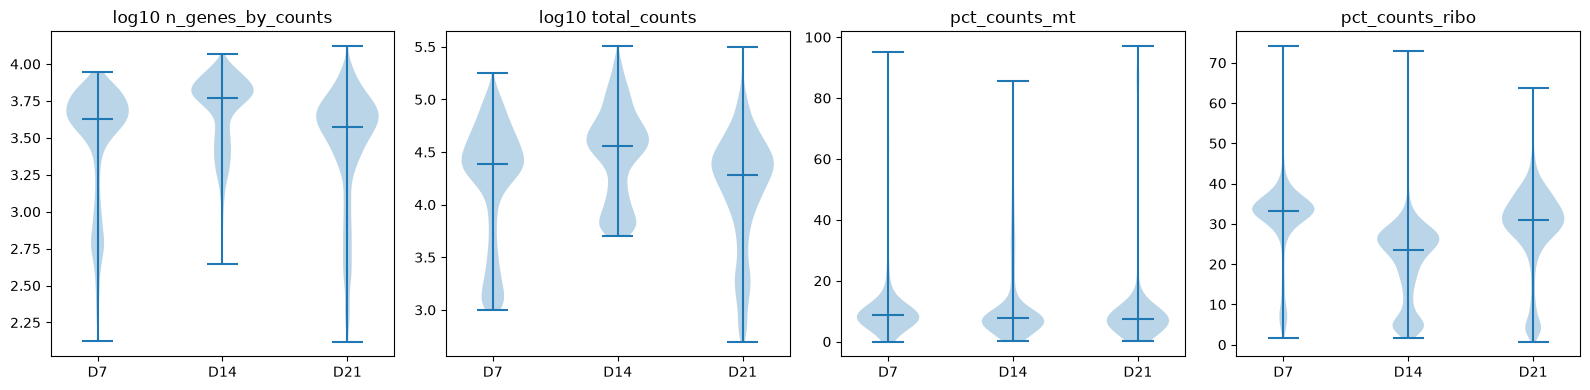

In [4]:
metrics = ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))             # 1 row, 4 panels
for ax, m in zip(axes, metrics):
    data = []
    for s in labels:
        vals = qc.loc[qc["timepoint"] == s, m].to_numpy()   # values of this metric for this sample
        if m in ("n_genes_by_counts", "total_counts"):
            vals = np.log10(vals)                           # log10 so the violin shape is meaningful
        data.append(vals)
    ax.violinplot(data, showmedians=True)                   # one violin per sample
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(labels)
    ax.set_title(("log10 " if m in ("n_genes_by_counts", "total_counts") else "") + m)
fig.tight_layout()
fig.savefig(fig_dir / "qc_violin_before_filtering.png", dpi=200, bbox_inches="tight")
plt.show()

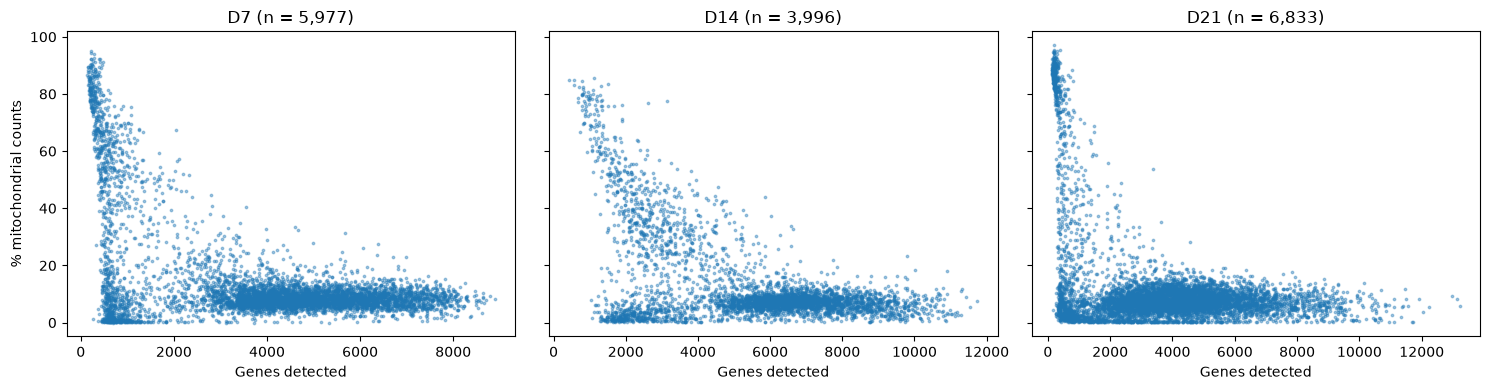

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)   # shared y-axis so samples are comparable
for ax, s in zip(axes, labels):
    d = qc[qc["timepoint"] == s]                               # rows of this sample only
    ax.scatter(d["n_genes_by_counts"], d["pct_counts_mt"], s=3, alpha=0.4)  # one dot per cell
    ax.set_xlabel("Genes detected")
    ax.set_title(f"{s} (n = {len(d):,})")
axes[0].set_ylabel("% mitochondrial counts")
fig.tight_layout()
fig.savefig(fig_dir / "qc_scatter_before_filtering.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
qc = pd.read_csv(result_dir / "qc_metrics_before_filtering.csv", index_col=0)   # QC table saved in Cell 2

mt_cuts   = [10, 15, 20, 25]            # candidate upper limits for % mitochondrial counts
gene_cuts = [500, 1000, 1500, 2000]     # candidate lower limits for number of detected genes

for s in labels:                        # one table per sample
    d = qc[qc["timepoint"] == s]
    rows = {}
    for g in gene_cuts:                 # each row = a minimum gene count
        rows[f"genes >= {g}"] = [int(((d["pct_counts_mt"] < m) & (d["n_genes_by_counts"] >= g)).sum())
                                 for m in mt_cuts]   # each column = a maximum % mito
    table = pd.DataFrame(rows, index=[f"mt < {m}%" for m in mt_cuts]).T
    print(f"\n{s}: cells kept (out of {len(d):,})")
    print(table)


D7: cells kept (out of 5,977)
               mt < 10%  mt < 15%  mt < 20%  mt < 25%
genes >= 500       3739      4856      5076      5183
genes >= 1000      3404      4467      4652      4737
genes >= 1500      3313      4361      4540      4619
genes >= 2000      3269      4307      4476      4552

D14: cells kept (out of 3,996)
               mt < 10%  mt < 15%  mt < 20%  mt < 25%
genes >= 500       2821      3176      3285      3375
genes >= 1000      2821      3176      3285      3375
genes >= 1500      2786      3139      3246      3336
genes >= 2000      2667      3017      3121      3209

D21: cells kept (out of 6,833)
               mt < 10%  mt < 15%  mt < 20%  mt < 25%
genes >= 500       4718      5847      5999      6051
genes >= 1000      4431      5519      5649      5683
genes >= 1500      4259      5334      5454      5480
genes >= 2000      4045      5106      5220      5242


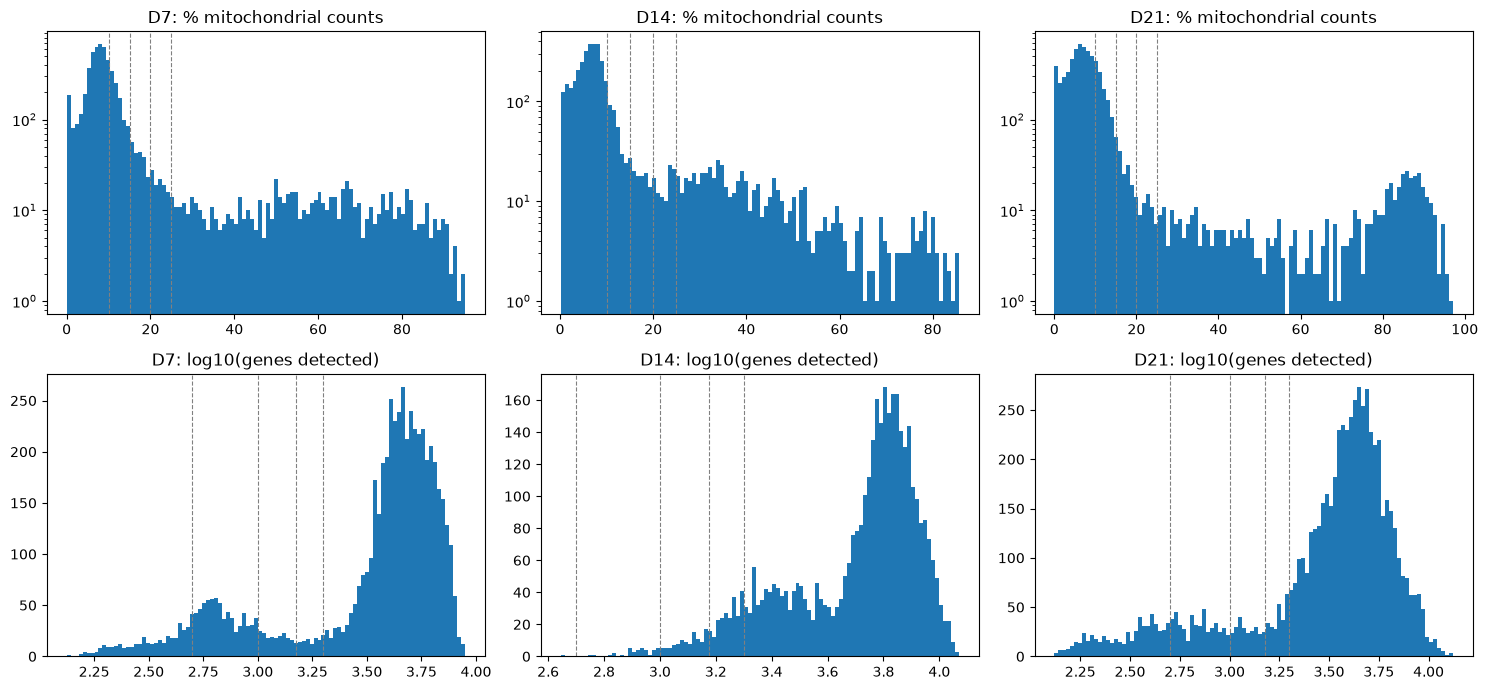

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, s in enumerate(labels):
    d = qc[qc["timepoint"] == s]
    # Top row: % mitochondrial counts; log y-axis keeps the small high-mito tail visible
    axes[0, j].hist(d["pct_counts_mt"], bins=100)
    axes[0, j].set_yscale("log")
    for m in mt_cuts:
        axes[0, j].axvline(m, linestyle="--", linewidth=0.8, color="grey")   # candidate cut-offs
    axes[0, j].set_title(f"{s}: % mitochondrial counts")
    # Bottom row: log10 of genes detected; a valley between two peaks suggests a natural cut-off
    axes[1, j].hist(np.log10(d["n_genes_by_counts"]), bins=100)
    for g in gene_cuts:
        axes[1, j].axvline(np.log10(g), linestyle="--", linewidth=0.8, color="grey")
    axes[1, j].set_title(f"{s}: log10(genes detected)")
fig.tight_layout()
fig.savefig(fig_dir / "qc_threshold_histograms.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# One dictionary entry per sample, so each sample can be tuned separately if needed
thresholds = {
    "D7":  {"max_mt": 20, "min_genes": 1500},    # keep cells with < 20 % mitochondrial counts and >= 1500 genes
    "D14": {"max_mt": 20, "min_genes": 1500},
    "D21": {"max_mt": 20, "min_genes": 1500},
}

for s in labels:
    d = qc[qc["timepoint"] == s]                 # QC table of this sample only
    t = thresholds[s]
    # Both conditions must be True for a cell to be kept ("&" means AND)
    keep = (d["pct_counts_mt"] < t["max_mt"]) & (d["n_genes_by_counts"] >= t["min_genes"])
    print(f"{s}: keep {int(keep.sum()):,} of {len(d):,} ({keep.mean():.0%})")

D7: keep 4,540 of 5,977 (76%)
D14: keep 3,246 of 3,996 (81%)
D21: keep 5,454 of 6,833 (80%)


In [9]:
summary = []                                              # one row of counts per sample

for s in labels:
    a = sc.read_h5ad(proc_dir / f"{s}_cells.h5ad")        # load one sample at a time to save RAM
    a.var["mt"] = a.var_names.str.startswith("MT-")       # flag mitochondrial genes
    # Recompute QC metrics (they were not stored inside the .h5ad files)
    sc.pp.calculate_qc_metrics(a, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
    t = thresholds[s]
    keep = (a.obs["pct_counts_mt"] < t["max_mt"]) & (a.obs["n_genes_by_counts"] >= t["min_genes"])
    n_before = a.n_obs                                    # number of cells before filtering
    a = a[keep].copy()                                    # keep only cells passing both thresholds
    a.write_h5ad(proc_dir / f"{s}_qc.h5ad")               # save the filtered sample
    summary.append({"sample": s, "cells_before": n_before, "cells_after": a.n_obs,
                    "max_mt_pct": t["max_mt"], "min_genes": t["min_genes"]})
    print(s, a.shape)
    del a                                                 # free memory before the next sample
    gc.collect()

summary = pd.DataFrame(summary)
summary.to_csv(result_dir / "qc_filtering_summary.csv", index=False)   # small table, safe for GitHub
print(summary)

D7 (4540, 36601)
D14 (3246, 36601)
D21 (5454, 36601)
  sample  cells_before  cells_after  max_mt_pct  min_genes
0     D7          5977         4540          20       1500
1    D14          3996         3246          20       1500
2    D21          6833         5454          20       1500
